![](img/banner.png)

# Neural Networks and Backpropagation

**Mahmood Amintoosi, Fall 2026**

Computer Science Dept, Ferdowsi University of Mashhad

I should mention that the original material was from [Tomas Beuzen's course](https://ubc-mds.github.io/DSCI_572_sup-learn-2).


## Lecture Learning Objectives

<hr>


- Describe the difference between `numpy` and `torch` arrays (`np.array` vs. `torch.Tensor`)
- Explain fundamental concepts of neural networks such as layers, nodes, activation functions, etc.
- Create a simple neural network in PyTorch for regression or classification
- Derive the gradients of a small network by hand and check them with `backward()`


## Imports

<hr>


In [1]:
# Auto-setup when running on Google Colab
import os
if 'google.colab' in str(get_ipython()) and not os.path.exists('/content/neural-networks'):
    !git clone -q https://github.com/fum-cs/neural-networks.git /content/neural-networks
    !pip --quiet install -r /content/neural-networks/requirements_colab.txt
    %cd neural-networks/notebooks

In [2]:
import warnings
warnings.filterwarnings('ignore')
import sys
import numpy as np
import pandas as pd
import torch
from torchsummary import summary
from torch import nn, optim
from torch.utils.data import DataLoader, TensorDataset
from sklearn.datasets import make_regression, make_circles, make_blobs
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from utils.plotting import *
import plotly.io as pio
pio.renderers.default = 'notebook'

## 1. Introduction

<hr>


- PyTorch is a Python-based tool for scientific computing that provides several main features:
  - `torch.Tensor`, an n-dimensional array similar to that of `numpy`, but which can run on GPUs
  - Computational graphs for building neural networks
  - Automatic differentiation for training neural networks (more on this next lecture)
- You can install PyTorch from: https://pytorch.org/


## 2. PyTorch's Tensor

<hr>


- In PyTorch a tensor is just like NumPy's `ndarray` that we have become so familiar with.
- A key difference between PyTorch's `torch.Tensor` and numpy's `np.array` is that `torch.Tensor` was constructed to integrate with GPUs and PyTorch's computational graphs (more on that next lecture though)


### 2.1. `ndarray` vs `tensor`


- Creating and working with tensors is much the same as with numpy `ndarrays`
- You can create a tensor with `torch.tensor()`:


In [3]:
tensor_1 = torch.tensor([1, 2, 3])
tensor_2 = torch.tensor([1, 2, 3], dtype=torch.float32)
tensor_3 = torch.tensor(np.array([1, 2, 3]))

for t in [tensor_1, tensor_2, tensor_3]:
    print(f"{t}, dtype: {t.dtype}")

tensor([1, 2, 3]), dtype: torch.int64
tensor([1., 2., 3.]), dtype: torch.float32
tensor([1, 2, 3], dtype=torch.int32), dtype: torch.int32


- PyTorch also comes with most of the `numpy` functions we're already familiar with:


In [4]:
torch.zeros(2, 2)  # zeroes

tensor([[0., 0.],
        [0., 0.]])

In [5]:
torch.ones(2, 2)  # ones

tensor([[1., 1.],
        [1., 1.]])

In [6]:
torch.randn(3, 2)  # random normal

tensor([[ 0.3388,  0.0180],
        [-0.1241,  0.9065],
        [-1.6244,  0.1037]])

In [7]:
torch.rand(2, 3, 2)  # rand uniform

tensor([[[0.8185, 0.1055],
         [0.7195, 0.2424],
         [0.8114, 0.7107]],

        [[0.8324, 0.9311],
         [0.1115, 0.8091],
         [0.0066, 0.2076]]])

- Just like in NumPy we can look at the shape of a tensor with the `.shape` attribute:


In [8]:
x = torch.rand(2, 3, 2, 2)
x.shape

torch.Size([2, 3, 2, 2])

In [9]:
x.ndim

4

### 2.2. Tensors and Data Types


- Different dtypes have different memory and computational implications (see [NumPy's data types documentation](https://numpy.org/doc/stable/user/basics.types.html) for more)
- In Pytorch we'll be building networks that require thousands or even millions of floating point calculations!
- In such cases, using a smaller dtype like `float32` can significantly speed up computations and reduce memory requirements
- The default float dtype in pytorch `float32`, as opposed to numpy's `float64`
- In fact some operations in Pytorch will even throw an error if you pass a high-memory `dtype`!


In [10]:
print(np.array([3.14159]).dtype)
print(torch.tensor([3.14159]).dtype)

float64
torch.float32


- But just like in numpy, you can always specify the particular dtype you want using the `dtype` argument:


In [11]:
print(torch.tensor([3.14159], dtype=torch.float64).dtype)

torch.float64


### 2.3. Operations on Tensors


- Tensors operate just like `ndarrays` and have a variety of familiar methods that can be called off them:


In [12]:
a = torch.rand(1, 3)
b = torch.rand(3, 1)

a + b  # broadcasting betweean a 1 x 3 and 3 x 1 tensor

tensor([[0.6376, 0.8497, 0.5364],
        [0.1417, 0.3538, 0.0404],
        [0.8795, 1.0915, 0.7782]])

In [13]:
a * b

tensor([[5.5718e-02, 1.6878e-01, 1.7360e-03],
        [3.8856e-03, 1.1771e-02, 1.2106e-04],
        [8.0994e-02, 2.4535e-01, 2.5235e-03]])

In [14]:
a.mean()

tensor(0.1415)

In [15]:
a.sum()

tensor(0.4244)

### 2.4. Indexing


- Once again, same as NumPy!


In [16]:
X = torch.rand(5, 2)
print(X)

tensor([[0.5512, 0.5119],
        [0.8011, 0.4224],
        [0.1395, 0.0438],
        [0.5987, 0.7250],
        [0.2124, 0.4778]])


In [17]:
print(X[0, :])
print(X[0])
print(X[:, 0])

tensor([0.5512, 0.5119])
tensor([0.5512, 0.5119])
tensor([0.5512, 0.8011, 0.1395, 0.5987, 0.2124])


### 2.5. Numpy Bridge


- Sometimes we might want to convert a tensor back to a NumPy array
- We can do that using the `.numpy()` method


In [18]:
X = torch.rand(3,3)
print(type(X))
X_numpy = X.numpy()
print(type(X_numpy))

<class 'torch.Tensor'>
<class 'numpy.ndarray'>


### 2.6. GPU and CUDA Tensors


- GPU is a graphical processing unit (as opposed to a CPU: central processing unit)
- GPUs were originally developed for gaming, they are very fast at performing operations on large amounts of data by performing them in parallel (think about updating the value of all pixels on a screen very quickly as a player moves around in a game)
- More recently, GPUs have been adapted for more general purpose programming
- Neural networks can typically be broken into smaller computations that can be performed in parallel on a GPU
- PyTorch is tightly integrated with CUDA - a software layer that facilitates interactions with a GPU (if you have one)
- You can check if you have GPU capability using:


In [19]:
torch.cuda.is_available()  # my MacBook Pro does not have a GPU

False

- When training on a machine that has a GPU, you need to tell PyTorch you want to use it
- You'll see the following at the top of most PyTorch code:


In [20]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device)

cpu


- You can then use the `device` argument when creating tensors to specify whether you wish to use a CPU or GPU
- Or if you want to move a tensor between the CPU and GPU, you can use the `.to()` method:


In [21]:
X = torch.rand(2, 2, 2, device=device)
print(X.device)

cpu


In [22]:
# X.to('cuda')  # this would give an error for me so I'm commenting out

- We'll revisit GPUs later in the course when we are working with bigger datasets and more complex networks
- For now, we can work on the CPU just fine


## 3. Neural Network Basics

<hr>


- You've already learned about several machine learning algorithms (kNN, Random Forest, SVM, etc.)
- Neural networks are simply another algorithm and actually one of the simplest in my opinion!
- As we'll see, a neural network is just a sequence of linear and non-linear transformations
- Often you see something like this when learning about/using neural networks:

![](img/nn-6.png)

- So what on Earth does that all mean? Well we are going to build up some intuition one step at a time


### 3.1. Simple Linear Regression with a Neural Network


- Let's create a simple regression dataset with 500 observations:


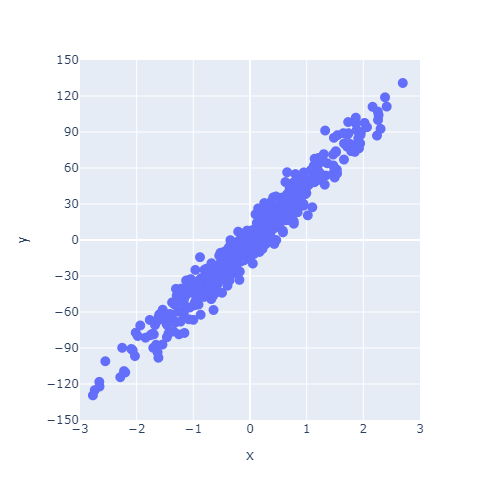

In [23]:
X, y = make_regression(n_samples=500, n_features=1, random_state=0, noise=10.0)
plot_regression(X, y)

- We know how to fit a simple linear regression to this data using sklearn:


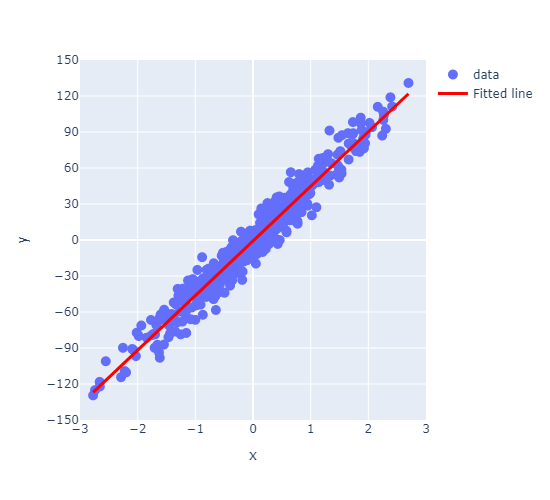

In [24]:
sk_model = LinearRegression().fit(X, y)
plot_regression(X, y, sk_model.predict(X))

- Here are the parameters of that fitted line:


In [25]:
print(f"w_0: {sk_model.intercept_:.2f} (bias/intercept)")
print(f"w_1: {sk_model.coef_[0]:.2f}")

w_0: -0.77 (bias/intercept)
w_1: 45.50


- As an equation, that looks like this:

$$\hat{y}=-0.77 + 45.50X$$

- Or in matrix form:

$$\begin{bmatrix} \hat{y_1} \\ \hat{y_2} \\ \vdots \\ \hat{y_n} \end{bmatrix}=\begin{bmatrix} 1 & x_1 \\ 1 & x_2 \\ \vdots & \vdots \\ 1 & x_n \end{bmatrix} \begin{bmatrix} -0.77 \\ 45.50 \end{bmatrix}$$

- Or in graph form I'll represent it like this:

![](img/nn-1.png)


### 3.2. Linear Regression with a Neural Network in PyTorch


- So let's implement the above in PyTorch to start gaining an intuition about neural networks!
- Every neural network model you build in PyTorch will inherit from `torch.nn.Module`
- Inheritance allows us to inherit commonly needed functionality without having to write code ourselves! [W3 Schools](https://www.w3schools.com/python/python_inheritance.asp) has a good mini tutorial for class inhertance in Python.

> We'll explore `torch.nn.Module` more in the lab but if it helps, think about sklearn models: they all inherit common methods like `.fit()`, `.predict()`, `.score()`, etc. When creating a neural network, we define our own architecture but still want common functionality which we inherit from `torch.nn.Module`.

- Let's create a model called `linearRegression` and then I'll talk you through the syntax:


In [26]:
class linearRegression(nn.Module):  # our class inherits from nn.Module and we can call it anything we like
    def __init__(self, input_size, output_size):
        super().__init__()                                # super().__init__() makes our class inherit everything from torch.nn.Module
        self.linear = nn.Linear(input_size, output_size)  # this is a simple linear layer: wX + b

    def forward(self, x):
        out = self.linear(x)
        return out

Let's step through the above:

```python
class linearRegression(nn.Module):
    def __init__(self, input_size, output_size):
        super().__init__()
```

Here we're creating a class called `linearRegression` and inheriting the methods and attributes of `nn.Module` (hint: try typing `help(linearRegression)` to see all the things we inheritied from `nn.Module`).

```python
        self.linear = nn.Linear(input_size, output_size)
```

Here we're defining a "Linear" layer, which just means `wX + b`, i.e., the weights of the network, multiplied by the input features plus the bias.

```python
    def forward(self, x):
        out = self.linear(x)
        return out
```

PyTorch networks created with `nn.Module` must have a `forward()` method. It accepts the input data `x` and passes it through the defined operations. In this case, we are passing `x` into our linear layer and getting an output `out`.


- After defining the model class, we can create an instance of that class:


In [27]:
model = linearRegression(input_size=1, output_size=1)

![](img/nn-2.png)


- We can check out our model using `print()`:


In [28]:
print(model)

linearRegression(
  (linear): Linear(in_features=1, out_features=1, bias=True)
)


- Or the more useful `summary()` (which we imported at the top of this notebook with `from torchsummary import summary`):


In [29]:
summary(model, (1,));

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Linear-1                    [-1, 1]               2
Total params: 2
Trainable params: 2
Non-trainable params: 0
----------------------------------------------------------------
Input size (MB): 0.00
Forward/backward pass size (MB): 0.00
Params size (MB): 0.00
Estimated Total Size (MB): 0.00
----------------------------------------------------------------


- Notice how we have two parameters? We have one for the weight (`w1`) and one for the bias (`w0`)
- These were initialized randomly by PyTorch when we created our model. They can be accessed with `model.state_dict()`:


In [30]:
model.state_dict()

OrderedDict([('linear.weight', tensor([[0.3072]])),
             ('linear.bias', tensor([-0.9891]))])

- Okay, before we move on, our `x` and `y` data are currently numpy arrays but they need to be PyTorch tensors
- Let's convert them:


In [31]:
X_t = torch.tensor(X, dtype=torch.float32)
y_t = torch.tensor(y, dtype=torch.float32)

- We have a working model right now and could tell it to give us some output with this syntax:


In [32]:
y_p = model(X_t[0]).item()
print(f"Predicted: {y_p:.2f}")
print(f"   Actual: {y[0]:.2f}")

Predicted: -0.80
   Actual: 31.08


- Our prediction is pretty bad because our model is not trained/fitted yet!
- As we learned in the past few lectures, to fit our model we need:
  1. **a loss function** (called "criterion" in PyTorch) to tell us how good/bad our predictions are - we'll use mean squared error, `torch.nn.MSELoss()`
  2. **an optimization algorithm** to help optimise model parameters - we'll use GD, `torch.optim.SGD()`


In [33]:
LEARNING_RATE = 0.1
criterion = nn.MSELoss()  # loss function
optimizer = torch.optim.SGD(model.parameters(), lr=LEARNING_RATE)  # optimization algorithm is SGD

- Before we train I'm going to create a "data loader" to help batch my data
- [Data loaders](https://pytorch.org/tutorials/beginner/basics/data_tutorial.html) are just generators that [yield](https://www.geeksforgeeks.org/use-yield-keyword-instead-return-keyword-python/) data to us on request.
- We'll use a `BATCH_SIZE = 50` (which should give us 10 batches because we have 500 data points)


In [34]:
BATCH_SIZE = 50
dataset = TensorDataset(X_t, y_t)
dataloader = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=True)

- We should have 10 batches:


In [35]:
print(f"Total number of batches: {len(dataloader)}")

Total number of batches: 10


- We can look at a batch using this syntax:


In [36]:
XX, yy = next(iter(dataloader))
print(f" Shape of feature data (X) in batch: {XX.shape}")
print(f"Shape of response data (y) in batch: {yy.shape}")

 Shape of feature data (X) in batch: torch.Size([50, 1])
Shape of response data (y) in batch: torch.Size([50])


- With those, let's train our simple network for 5 epochs of SGD!
  > We open this block line by line in Section 5; for now just note that it computes a loss, asks for gradients and takes a step.


In [37]:
def trainer(model, criterion, optimizer, dataloader, epochs=5, verbose=True):
    """Simple training wrapper for PyTorch network."""
    
    for epoch in range(epochs):
        losses = 0
        for X, y in dataloader:
            optimizer.zero_grad()       # Clear gradients w.r.t. parameters
            y_hat = model(X).flatten()  # Forward pass to get output
            loss = criterion(y_hat, y)  # Calculate loss
            loss.backward()             # Getting gradients w.r.t. parameters
            optimizer.step()            # Update parameters
            losses += loss.item()       # Add loss for this batch to running total
        if verbose: print(f"epoch: {epoch + 1}, loss: {losses / len(dataloader):.4f}")
   
trainer(model, criterion, optimizer, dataloader, epochs=5, verbose=True)

epoch: 1, loss: 648.7896
epoch: 2, loss: 99.0878
epoch: 3, loss: 94.1367
epoch: 4, loss: 93.6165
epoch: 5, loss: 93.4385


- Now our model has been trained, our parameters should be different than before:


In [38]:
model.state_dict()

OrderedDict([('linear.weight', tensor([[45.7395]])),
             ('linear.bias', tensor([-0.7178]))])

- Comparing to our sklearn model, we get the same answer:


In [39]:
pd.DataFrame({"w0": [sk_model.intercept_, model.state_dict()['linear.bias'].item()],
              "w1": [sk_model.coef_[0], model.state_dict()['linear.weight'].item()]},
             index=['sklearn', 'pytorch']).round(2)

,w0,w1
sklearn,-0.77,45.50
pytorch,-0.72,45.74


- We got pretty close! We could do better by changing the number of epochs or the learning rate
- So here is our simple network once again:

![](img/nn-2.png)


- By the way, check out what happens if we run `trainer()` again:


In [40]:
trainer(model, criterion, optimizer, dataloader, epochs=5, verbose=True)

epoch: 1, loss: 93.5241
epoch: 2, loss: 94.1431
epoch: 3, loss: 93.9253
epoch: 4, loss: 93.4623
epoch: 5, loss: 93.8662


- Our model continues where we left off!
- This may or may not be what you want. We can start from scratch by re-making our `model` and `optimizer`.


### 3.3. Multiple Linear Regression with a Neural Network


- Okay, let's do a multiple linear regression now with 3 features
- So our network will look like this:

![](img/nn-3.png)

- Let's go ahead and create some data:


In [41]:
# Create dataset
X, y = make_regression(n_samples=500, n_features=3, random_state=0, noise=10.0)
X_t = torch.tensor(X, dtype=torch.float32)
y_t = torch.tensor(y, dtype=torch.float32)
# Create dataloader
dataset = TensorDataset(X_t, y_t)
dataloader = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=True)

- And let's create the above model:


In [42]:
model = linearRegression(input_size=3, output_size=1)

- We should now have 4 parameters (3 weights and 1 bias)


In [43]:
summary(model, (3,));

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Linear-1                    [-1, 1]               4
Total params: 4
Trainable params: 4
Non-trainable params: 0
----------------------------------------------------------------
Input size (MB): 0.00
Forward/backward pass size (MB): 0.00
Params size (MB): 0.00
Estimated Total Size (MB): 0.00
----------------------------------------------------------------


- Looks good to me! Let's train the model and then compare it to sklearn's `LinearRegression()`:


In [44]:
criterion = nn.MSELoss()
optimizer = torch.optim.SGD(model.parameters(), lr=LEARNING_RATE)
trainer(model, criterion, optimizer, dataloader, epochs=5, verbose=True)

epoch: 1, loss: 1007.8107
epoch: 2, loss: 110.3681
epoch: 3, loss: 102.1059
epoch: 4, loss: 101.9216
epoch: 5, loss: 102.1261


In [45]:
sk_model = LinearRegression().fit(X, y)
pd.DataFrame({"w0": [sk_model.intercept_, model.state_dict()['linear.bias'].item()],
              "w1": [sk_model.coef_[0], model.state_dict()['linear.weight'][0, 0].item()],
              "w2": [sk_model.coef_[1], model.state_dict()['linear.weight'][0, 1].item()],
              "w3": [sk_model.coef_[2], model.state_dict()['linear.weight'][0, 2].item()]},
             index=['sklearn', 'pytorch']).round(2)

,w0,w1,w2,w3
sklearn,0.43,0.62,55.99,11.14
pytorch,0.82,0.60,56.06,11.19


### 3.4. Non-linear Regression with a Neural Network


- Okay so we can make a simple network to imitate simple and multiple _linear_ regression
- You're probably thinking, so what? But we're getting to the good stuff I promise!
- For example, what happens when we have more complicated datasets like this?


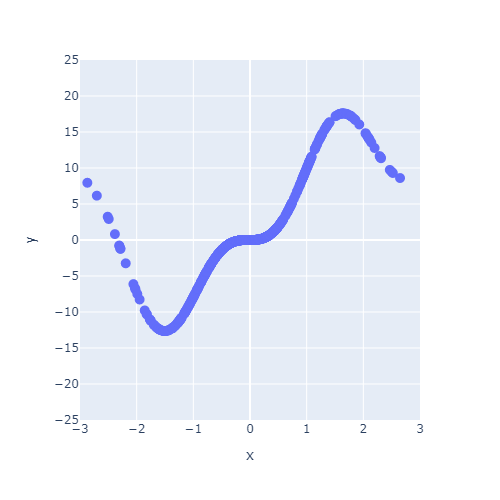

In [46]:
# Create dataset
np.random.seed(2020)
X = np.sort(np.random.randn(500))
y = X ** 2 + 15 * np.sin(X) **3
X_t = torch.tensor(X[:, None], dtype=torch.float32)
y_t = torch.tensor(y, dtype=torch.float32)
# Create dataloader
dataset = TensorDataset(X_t, y_t)
dataloader = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=True)
plot_regression(X, y, y_range=[-25, 25], dy=5)

- This is obviously non-linear, and we need to introduce some **non-linearities** into our network
- These non-linearities are what make neural networks so powerful and they are called **"activation functions"**
- We are going to create a new model class that includes a non-linearity - a sigmoid function:

$$S(X)=\frac{1}{1+e^{-x}}$$


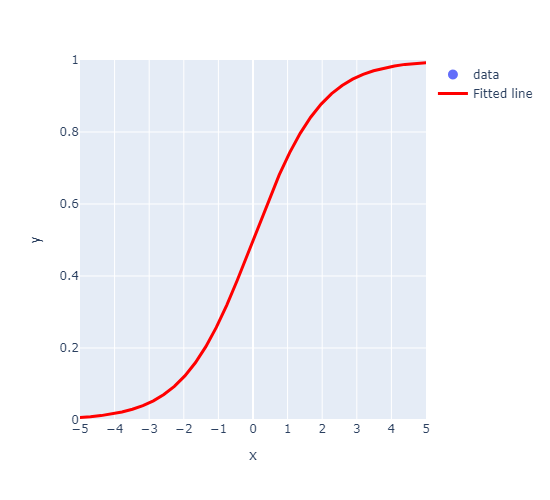

In [47]:
def sigmoid(x):
    return 1 / (1 + np.exp(-x))

xs = np.linspace(-15, 15, 100)
plot_regression(xs, [0], sigmoid(xs), x_range=[-5, 5], y_range=[0, 1], dy=0.2)

- We'll talk more about activation functions later, but note how the sigmoid function non-linearly maps `x` to a value between 0 and 1
- Okay, so let's create the following network:


![](img/nn-5.png)


- All this means is that the value of each node in the hidden layer will be transformed by the "activation function", thus introducing non-linear elements to our model!
- There's two main ways of creating the above model in PyTorch, I'll show you both:


In [48]:
class nonlinRegression(nn.Module):
    def __init__(self, input_size, hidden_size, output_size):
        super().__init__()
        self.hidden = nn.Linear(input_size, hidden_size)
        self.output = nn.Linear(hidden_size, output_size)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        x = self.hidden(x)       # input -> hidden layer
        x = self.sigmoid(x)      # sigmoid activation function in hidden layer
        x = self.output(x)       # hidden -> output layer
        return x

- Note how our `forward()` method now passes `x` through the `nn.Sigmoid()` function after the hidden layer
- The above method is very clear and flexible, but I prefer using `nn.Sequential()` to combine my layers together in the constructor:


In [49]:
class nonlinRegression(nn.Module):
    def __init__(self, input_size, hidden_size, output_size):
        super().__init__()
        self.main = torch.nn.Sequential(
            nn.Linear(input_size, hidden_size),  # input -> hidden layer
            nn.Sigmoid(),                        # sigmoid activation function in hidden layer
            nn.Linear(hidden_size, output_size)  # hidden -> output layer
        )

    def forward(self, x):
        x = self.main(x)
        return x

- Let's make an instance of our new class and confirm it has 10 parameters (6 weights + 4 biases):


In [50]:
model = nonlinRegression(1, 3, 1)
summary(model, (1,))

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Linear-1                    [-1, 3]               6
           Sigmoid-2                    [-1, 3]               0
            Linear-3                    [-1, 1]               4
Total params: 10
Trainable params: 10
Non-trainable params: 0
----------------------------------------------------------------
Input size (MB): 0.00
Forward/backward pass size (MB): 0.00
Params size (MB): 0.00
Estimated Total Size (MB): 0.00
----------------------------------------------------------------


- Okay, let's train:


In [51]:
criterion = nn.MSELoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.3)
trainer(model, criterion, optimizer, dataloader, epochs=10, verbose=True)

epoch: 1, loss: 32.5818
epoch: 2, loss: 14.8140
epoch: 3, loss: 7.6448
epoch: 4, loss: 5.2685
epoch: 5, loss: 4.8211
epoch: 6, loss: 4.7319
epoch: 7, loss: 4.4413
epoch: 8, loss: 4.2567
epoch: 9, loss: 4.3213
epoch: 10, loss: 4.2639


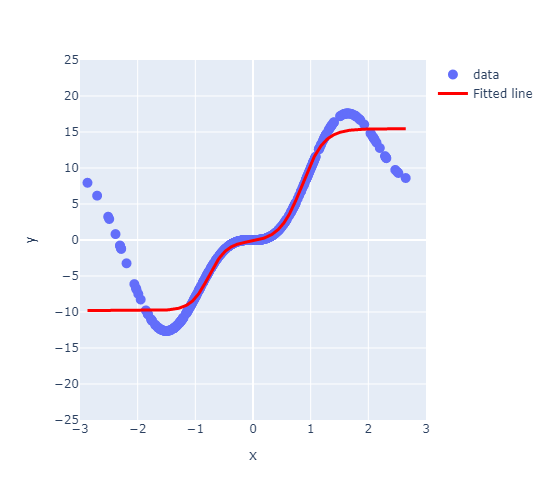

In [52]:
y_p = model(X_t).detach().numpy().squeeze()
plot_regression(X, y, y_p, y_range=[-25, 25], dy=5)

- Take a look at those non-linear predictions! Cool!
- Our model is not great and we could make it better soon by adjusting the learning rate, the number of nodes, and the number of epochs
- But I really want you to see how **each of our hidden nodes is "engineering a non-linear feature"** to be used for the predictions, check it out:


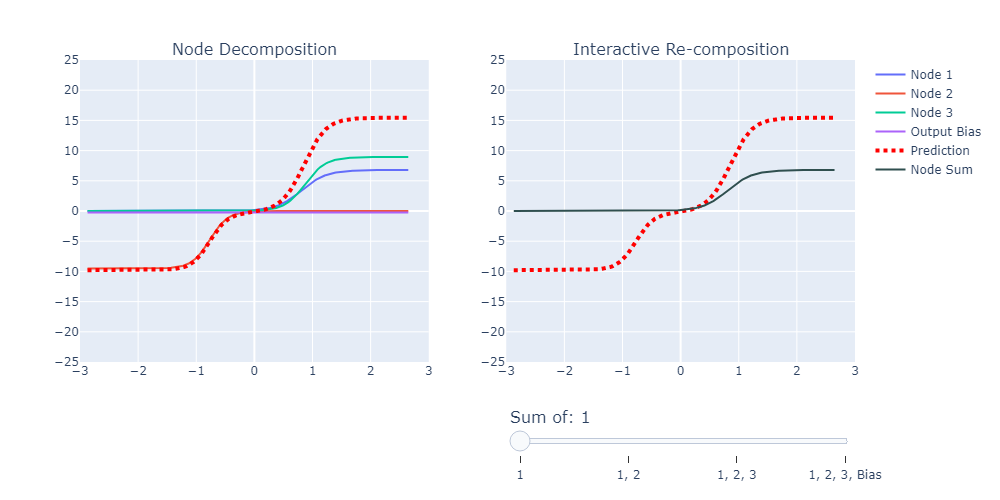

In [53]:
plot_nodes(X, y_p, model)

### 3.5. Multi Layer Perceptron


- You've probably heard the magic term "MLP" and you're about to find out what it means!
- Really, it's just a neural network with more than 1 hidden layer! Easy!
- Let's create an "MLP" network of 2 layers:

![](img/nn-6.png)


In [54]:
class multiLayerRegression(nn.Module):
    def __init__(self, input_size, hidden_size_1, hidden_size_2, output_size):
        super().__init__()
        self.main = nn.Sequential(
            nn.Linear(input_size, hidden_size_1),
            nn.Sigmoid(),
            nn.Linear(hidden_size_1, hidden_size_2),
            nn.Sigmoid(),
            nn.Linear(hidden_size_2, output_size)
        )

    def forward(self, x):
        out = self.main(x)
        return out

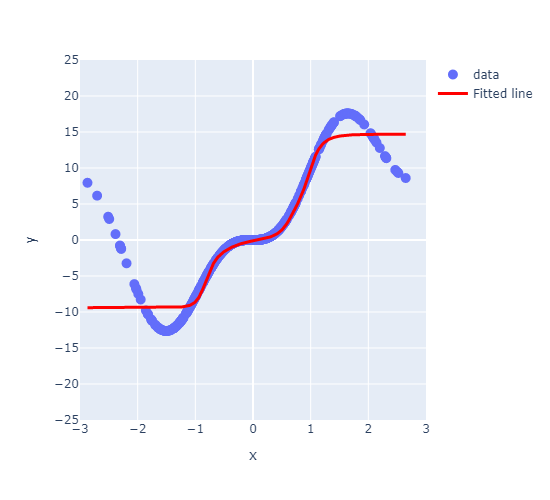

In [55]:
model = multiLayerRegression(1, 5, 3, 1)
optimizer = torch.optim.SGD(model.parameters(), lr=0.3)
trainer(model, criterion, optimizer, dataloader, epochs=20, verbose=False)
plot_regression(X, y, model(X_t).detach(), y_range=[-25, 25], dy=5)

- But just because the network has more layer, doesn't always mean it's better!


## 4. Activation Functions

<hr>


- As we learned above, activation functions are what allow us to model complex, non-linear functions
- There are **many** different activations functions:


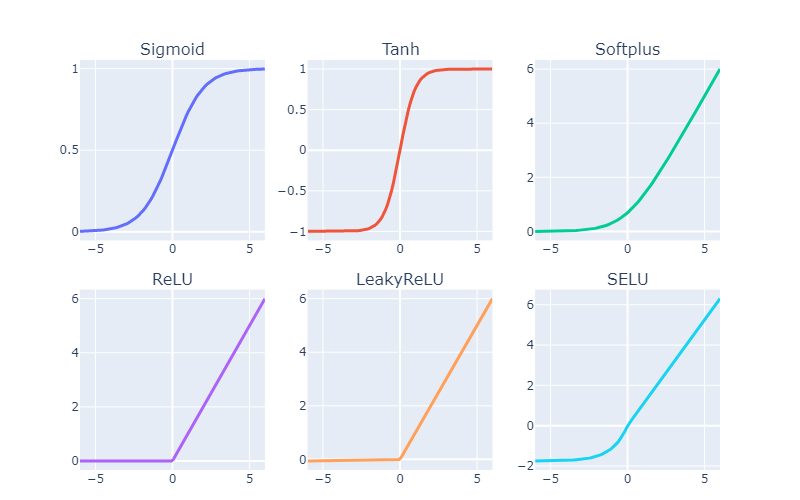

In [56]:
functions = [torch.nn.Sigmoid, torch.nn.Tanh, torch.nn.Softplus, torch.nn.ReLU, torch.nn.LeakyReLU, torch.nn.SELU]
plot_activations(torch.linspace(-6, 6, 100), functions)

- Activation functions should be non-linear and tend to be monotonic and continuously differentiable (smooth)
- But as you can see with the ReLU function above, that's not always the case!
- I wanted to point this out because it highlights how much of an art deep learning really is.
- Here's a great quote from [Yoshua Bengio](https://en.wikipedia.org/wiki/Yoshua_Bengio) (famous for his work in AI and deep learning) on his group experimenting with ReLU:

> "...one of the biggest mistakes I made was to think, like everyone else in the 90s, that you needed smooth non-linearities in order for backpropagation to work. because I thought that if we had something like rectifying nonlinearities, where you have a flat part, that it would be really hard to train, because the derivative would be zero in so many places. And when we started experimenting with ReLU, with deep nets around 2010, I was obsessed with the idea that, we should be careful about whether neurons won't saturate too much on the zero part. **But in the end, it turned out that, actually, the ReLU was working a lot better than the sigmoids and tanh, and that was a big surprise**...it turned out to work better, whereas I thought it would be harder to train!"

- Anyway, TL;DR **ReLU is probably the most popular these days**, but you can treat activation functions as hyperparams (to be optimized)


## 5. Backpropagation

<hr>


- Every network we have fitted so far was trained by the same short block of code, hidden inside `trainer()`:

```python
optimizer.zero_grad()        # 1. forget the gradients left by the previous batch
y_hat = model(X).flatten()   # 2. forward pass: compute the prediction
loss  = criterion(y_hat, y)  # 3. how wrong are we?
loss.backward()              # 4. backward pass: compute the gradients
optimizer.step()             # 5. move the parameters against the gradient
```

- The `loss.backward()` line is the one we have been treating as a black box. It is **backpropagation**: the chain rule, applied backwards through the network, one layer at a time.
- The trick is that the derivative of the loss with respect to the output is computed once and then *reused* by every parameter that contributed to that output. That is why one backward pass costs about as much as one forward pass, instead of one forward pass per parameter.
- To see this concretely, take the smallest network that is still non-linear: one input, two sigmoid hidden units and one output.

![](img/backprop-1.png)


### 5.1. The forward pass, by hand


- Fix the weights and biases as in the figure below, and feed the network a single observation $x=1$ with target $y=3$.

![](img/backprop-2.png)

- A forward pass is multiply, add, squash — twice:

$$z_1=w_1x+b_1=2,\qquad a_1=\sigma(z_1)=0.88$$
$$z_2=w_2x+b_2=1,\qquad a_2=\sigma(z_2)=0.73$$
$$\hat{y}=w_3a_1+w_4a_2+b_3=1.34,\qquad \mathcal{L}=(\hat{y}-y)^2=2.75$$

![](img/backprop-3.png)

- Nothing here is new: a linear layer, a sigmoid, another linear layer and a squared error, chained together.


### 5.2. The backward pass, by hand


- Start at the loss and ask how $\mathcal{L}$ changes when $\hat{y}$ changes. For the squared error, $\partial\mathcal{L}/\partial\hat{y}=2(\hat{y}-y)=-3.31$.
- That single number is the *upstream gradient*. Every parameter below it gets its own gradient by multiplying the upstream gradient by its **local** derivative:

![](img/backprop-4.png)

$$\frac{\partial\mathcal{L}}{\partial w_3}=\frac{\partial\mathcal{L}}{\partial\hat{y}}\,a_1=-2.91,\qquad
\frac{\partial\mathcal{L}}{\partial w_4}=\frac{\partial\mathcal{L}}{\partial\hat{y}}\,a_2=-2.42,\qquad
\frac{\partial\mathcal{L}}{\partial b_3}=\frac{\partial\mathcal{L}}{\partial\hat{y}}=-3.31$$

![](img/backprop-5.png)

- For the hidden layer we keep walking backwards: the output layer hands back the gradient with respect to each activation, and the sigmoid contributes its own derivative $\sigma'(z)=\sigma(z)\big(1-\sigma(z)\big)$. With $\sigma'(z_1)=0.105$ and $\sigma'(z_2)=0.197$:

$$\frac{\partial\mathcal{L}}{\partial a_1}=\frac{\partial\mathcal{L}}{\partial\hat{y}}\,w_3,\qquad
\frac{\partial\mathcal{L}}{\partial z_1}=\frac{\partial\mathcal{L}}{\partial a_1}\,\sigma'(z_1),\qquad
\frac{\partial\mathcal{L}}{\partial w_1}=\frac{\partial\mathcal{L}}{\partial z_1}\,x,\qquad
\frac{\partial\mathcal{L}}{\partial b_1}=\frac{\partial\mathcal{L}}{\partial z_1}$$

![](img/backprop-6.png)

- The same recipe on the second hidden unit gives $\partial\mathcal{L}/\partial w_2=\partial\mathcal{L}/\partial b_2=-1.30$, and the first one gives $\partial\mathcal{L}/\partial w_1=\partial\mathcal{L}/\partial b_1=-0.35$.

![](img/backprop-7.png)


### 5.3. The same gradients from PyTorch


- We can set the network to exactly the weights of the figure and let PyTorch do the bookkeeping. The numbers below should match the hand calculation to two decimals.


In [ ]:
torch.manual_seed(0)

net = nn.Sequential(nn.Linear(1, 2), nn.Sigmoid(), nn.Linear(2, 1))
with torch.no_grad():  # the weights of the figure, not random ones
    net[0].weight.copy_(torch.tensor([[1.0], [-1.0]]))
    net[0].bias.copy_(torch.tensor([1.0, 2.0]))
    net[2].weight.copy_(torch.tensor([[1.0, 2.0]]))
    net[2].bias.copy_(torch.tensor([-1.0]))

x, y = torch.tensor([[1.0]]), torch.tensor([[3.0]])
y_hat = net(x)
loss = (y_hat - y) ** 2
loss.backward()

print(f"y_hat = {y_hat.item():.4f}, loss = {loss.item():.4f}")
for name, p in net.named_parameters():
    print(f"{name:10s}", [round(g, 2) for g in p.grad.flatten().tolist()])


### 5.4. What this means for `trainer()`


- **Why the graph exists.** Parameters created by a `nn.Module` come with `requires_grad=True`, so PyTorch records every operation applied to them. Nothing else needs to be tracked: we want derivatives with respect to the parameters, not the data.
- **What `backward()` fills.** Before the call, `p.grad` is `None`; afterwards it holds $\partial\mathcal{L}/\partial p$ *for the current batch*. That is the whole output of backpropagation.
- **Why `zero_grad()` is there.** Gradients accumulate by default. If you forget it, the next batch adds its gradient to the previous one and the effective learning rate drifts.
- **What `step()` does.** For plain SGD, $p \leftarrow p-\eta\, p.\mathrm{grad}$, which is exactly Step 4 of the gradient descent procedure from the regression lecture.
- **Backpropagation is not the optimizer.** It only computes gradients; the same numbers can be handed to SGD, Adam or anything else.


## 6. Classification with Neural Networks
<hr>

### 6.1. Binary Classification

- This will actually be the easiest part of the lecture
- Up until now, we've been looking at developing networks for regression tasks, but what if we want to do binary classification?
- In logistic regression we passed the output of a linear model through the sigmoid to get a probability between 0 and 1. A network does the same thing, with a hidden layer in front of the sigmoid.
- Let's create a toy dataset:

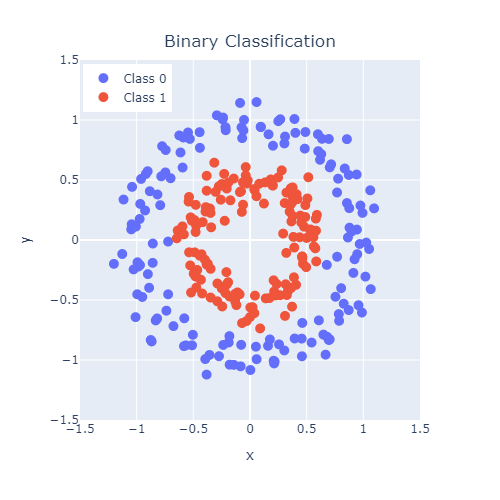

In [72]:
X, y = make_circles(n_samples=300, factor=0.5, noise=0.1, random_state=2020)
X_t = torch.tensor(X, dtype=torch.float32)
y_t = torch.tensor(y, dtype=torch.float32)
# Create dataloader
BATCH_SIZE = 50
dataset = TensorDataset(X_t, y_t)
dataloader = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=True)
plot_classification_2d(X, y)

- Let's create this network to model that dataset:

![](img/nn-7.png)

- I'm going to start using `ReLU` as our activation function(s) and `Adam` as our optimizer because these are what are currently, commonly used in practice.
- We are doing classification now so we'll need to use log loss (binary cross entropy) as our loss function:

$$f(w) = \sum_{x,y \in D} -y log(\hat{y}) - (1-y)log(1-\hat{y})$$

- In PyTorch, binary cross entropy loss criterion is `torch.nn.BCELoss`
- The formula expects a "probability" which is why we add a Sigmoid function to the end of out network.

In [73]:
class binaryClassifier(nn.Module):
    def __init__(self, input_size, hidden_size, output_size):
        super().__init__()
        self.main = nn.Sequential(
            nn.Linear(input_size, hidden_size),
            nn.ReLU(),
            nn.Linear(hidden_size, output_size),
            nn.Sigmoid()  # <-- this will squash our output to a probability between 0 and 1
        )

    def forward(self, x):
        out = self.main(x)
        return out

- **BUT WAIT!**
- While we can do the above and then train with a `torch.nn.BCELoss` loss function, there's a better way!
- We can omit the Sigmoid function and just use `torch.nn.BCEWithLogitsLoss` (which combines a Sigmoid layer and the BCELoss)
- Why would we do this? It's numerically stable! (Did you do the log-sum-exp question in Lab 1? We use it here for stability!)
- From the docs:
>"*This version is more numerically stable than using a plain Sigmoid followed by a BCELoss as, by combining the operations into one layer, we take advantage of the log-sum-exp trick for numerical stability.*"
- So actually, here's our model (no Sigmoid layer at the end because it's included in the loss function we'll use):

In [74]:
class binaryClassifier(nn.Module):
    def __init__(self, input_size, hidden_size, output_size):
        super().__init__()
        self.main = nn.Sequential(
            nn.Linear(input_size, hidden_size),
            nn.ReLU(),
            nn.Linear(hidden_size, output_size)
        )

    def forward(self, x):
        out = self.main(x)
        return out

- Let's train the model:

In [75]:
def trainer(model, criterion, optimizer, dataloader, epochs=5, verbose=True):
    """Simple training wrapper for PyTorch network."""
    
    for epoch in range(epochs):
        losses = 0
        for X, y in dataloader:
            optimizer.zero_grad()       # Clear gradients w.r.t. parameters
            y_hat = model(X).flatten()  # Forward pass to get output
            loss = criterion(y_hat, y)  # Calculate loss
            loss.backward()             # Getting gradients w.r.t. parameters
            optimizer.step()            # Update parameters
            losses += loss.item()       # Add loss for this batch to running total
        if verbose: print(f"epoch: {epoch + 1}, loss: {losses / len(dataloader):.4f}")

In [76]:
model = binaryClassifier(2, 5, 1)
LEARNING_RATE = 0.1
criterion = torch.nn.BCEWithLogitsLoss() # loss function
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)  # optimization algorithm
trainer(model, criterion, optimizer, dataloader, epochs=20, verbose=True)

epoch: 1, loss: 0.6842
epoch: 2, loss: 0.6534
epoch: 3, loss: 0.6097
epoch: 4, loss: 0.5676
epoch: 5, loss: 0.5343
epoch: 6, loss: 0.4916
epoch: 7, loss: 0.4410
epoch: 8, loss: 0.3871
epoch: 9, loss: 0.3299
epoch: 10, loss: 0.2833
epoch: 11, loss: 0.2467
epoch: 12, loss: 0.2135
epoch: 13, loss: 0.1992
epoch: 14, loss: 0.1889
epoch: 15, loss: 0.1800
epoch: 16, loss: 0.1695
epoch: 17, loss: 0.1698
epoch: 18, loss: 0.1687
epoch: 19, loss: 0.1541
epoch: 20, loss: 0.1510


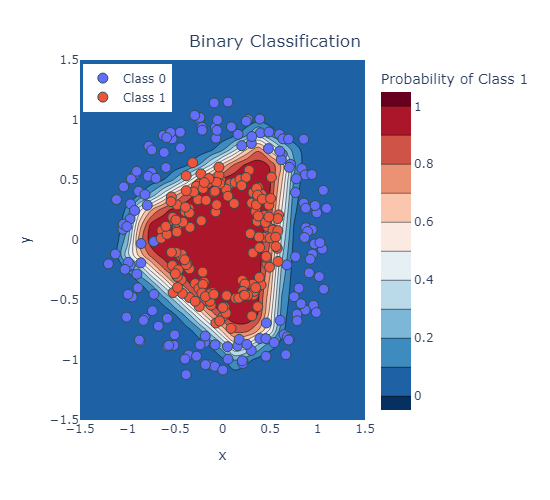

In [77]:
plot_classification_2d(X, y, model)

- To be clear, our model is just outputting some number between -∞ and +∞ (we aren't applying Sigmoid), so:
    - To get the probabilities we would need to pass them through a Sigmoid;
    - To get classes, we can apply some threshold (usually 0.5)
- For example, we would expect the point (0,0) to have a high probability and the point (-1,-1) to have a low probability:

In [78]:
prediction = model(torch.tensor([[0, 0], [-1, -1]], dtype=torch.float32)).detach()
print(prediction)

tensor([[  4.9344],
        [-11.3356]])


In [79]:
probability = nn.Sigmoid()(prediction)
print(probability)

tensor([[9.9286e-01],
        [1.1939e-05]])


In [80]:
classes = np.where(probability > 0.5, 1, 0)
print(classes)

[[1]
 [0]]


### 6.2. Multiclass Classification (Optional)

- For multiclass classification, remember softmax?

$$\sigma(\vec{z})_i=\frac{e^{z_i}}{\sum_{j=1}^{K}e^{z_j}}$$

- It basically makes sure all the outputs are probabilities between 0 and 1, and that they all sum to 1.
- `torch.nn.CrossEntropyLoss` is a loss that combines a softmax with cross entropy loss.
- Let's try a 4-class classification problem using the following network:

![](img/nn-8.png)

In [81]:
class multiClassifier(torch.nn.Module):
    def __init__(self, input_size, hidden_size, output_size):
        super().__init__()
        self.main = torch.nn.Sequential(
            torch.nn.Linear(input_size, hidden_size),
            torch.nn.ReLU(),
            torch.nn.Linear(hidden_size, output_size)
        )

    def forward(self, x):
        out = self.main(x)
        return out

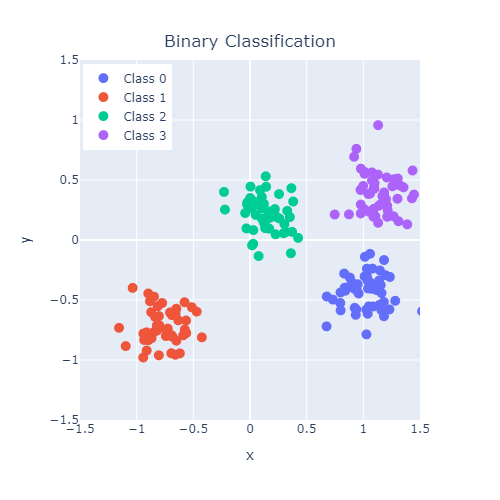

In [82]:
X, y = make_blobs(n_samples=200, centers=4, center_box=(-1.2, 1.2), cluster_std=[0.15, 0.15, 0.15, 0.15], random_state=12345)
X_t = torch.tensor(X, dtype=torch.float32)
y_t = torch.tensor(y, dtype=torch.int64)
# Create dataloader
dataset = TensorDataset(X_t, y_t)
dataloader = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=True)
plot_classification_2d(X, y)

- Let's train this model:

In [83]:
model = multiClassifier(2, 5, 4)
criterion = torch.nn.CrossEntropyLoss() # loss function
optimizer = torch.optim.Adam(model.parameters(), lr=0.2)  # optimization algorithm

for epoch in range(10):
    losses = 0
    for X_batch, y_batch in dataloader:
        optimizer.zero_grad()       # Clear gradients w.r.t. parameters
        y_hat = model(X_batch)            # Forward pass to get output
        loss = criterion(y_hat, y_batch)  # Calculate loss
        loss.backward()             # Getting gradients w.r.t. parameters
        optimizer.step()            # Update parameters
        losses += loss.item()       # Add loss for this batch to running total
    print(f"epoch: {epoch + 1}, loss: {losses / len(dataloader):.4f}")

epoch: 1, loss: 1.1576
epoch: 2, loss: 0.7209
epoch: 3, loss: 0.4848
epoch: 4, loss: 0.3222
epoch: 5, loss: 0.1632
epoch: 6, loss: 0.0652
epoch: 7, loss: 0.0157
epoch: 8, loss: 0.0085
epoch: 9, loss: 0.0040
epoch: 10, loss: 0.0016


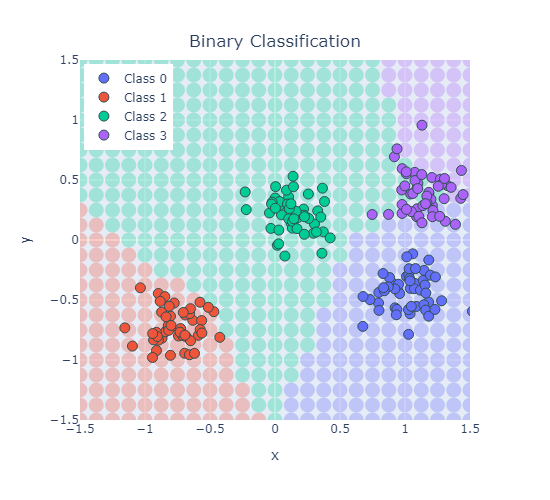

In [84]:
plot_classification_2d(X, y, model, transform="Softmax")

- To be clear once again, our model is just outputting some number between -∞ and +∞, so:
    - To get the probabilities we would need to pass them to a Softmax;
    - To get classes, we need to select the largest probability.
- For example, we would expect the point (-1,-1) to have a high probability of belonging to class 1, and the point (0,0) to have the highest probability of belonging to class 2.

In [85]:
prediction = model(torch.tensor([[-1, -1], [1,1]], dtype=torch.float32)).detach()
print(prediction)

tensor([[-27.5895,  19.3565,   1.1430, -33.1879],
        [-12.4731, -22.3387,   2.0026,  20.8498]])


- Note how we get 4 predictions per data point (a prediction for each of the 4 classes)

In [86]:
probability = nn.Softmax(dim=1)(prediction)
print(probability)

tensor([[4.0889e-21, 1.0000e+00, 1.2302e-08, 1.5144e-23],
        [3.3731e-15, 1.7517e-19, 6.5275e-09, 1.0000e+00]])


- The predictions should now sum to 1:

In [87]:
probability.sum(dim=1)

tensor([1., 1.])

- We can get the class with maximum probability using `argmax()`:

In [88]:
classes = probability.argmax(dim=1)
print(classes)

tensor([1, 3])


## 7. Lecture Exercise: True/False Questions

<hr>


Answer True/False for the following:

1. Neural networks can be used for both regression and classification. (**True**)
2. For fully connected neural networks, the number of parameters $\geq$ the number of features. (**True**)
3. Neural networks are parametric models. (**True**)
4. Any neural network with 3 hidden layers will have more parameters than any neural network with 2 hidden layers. (**False**)
5. The architecture of a neural network (number of hidden layers and hidden nodes) is a hyperparameter. (**True**)
6. Like linear regression or logistic regression, with neural networks we can interpret each feature's weight value as a measure of the feature's importance. (**False**)


## 8. The Lecture in Three Conjectures

<hr>


1. PyTorch is a neural network software based on "tensors" (like NumPy arrays on steroids).
2. Neural Networks are simply:
   - Composed of an input layer, 1 or more hidden layers, and an output layer, each with 1 or more nodes.
   - The number of nodes in the Input/Output layers is defined by the problem/data. Hidden layers can have an arbitrary number of nodes.
   - Activation functions in the hidden layers help us model non-linear data.
   - Feed-forward neural networks are just a combination of simple linear and non-linear operations.
3. Activation functions allow the network to learn non-linear function


## Exercises

1. Derive the gradients of a one-hidden-layer network $\hat y = w_2^\top\sigma(W_1x+b_1)+b_2$ with respect to $W_1,b_1,w_2,b_2$, then check each of the four against `autograd` on one fixed input.
2. Gradient check: compare the analytic gradient of one weight with a central finite difference $(f(w+h)-f(w-h))/2h$, plot the relative error against $h$ from $10^{-12}$ to $10^{-1}$, and explain the U-shape of the curve.
3. Replace the hidden activation by the identity, retrain the non-linear regression example of §3.4, and report the training and test error. Which property of the network does the collapse show?
4. A stack of linear layers is a single matrix: show that $W_3W_2W_1x = Wx$ and count the parameters of the deepest versus the shallowest version when the input and output both have dimension $10$. Which one has more freedom?

